# Dataset generation demo

`erosion_datagen` generates the erosion datasets. It lives in its own environment (Python 3.10,
numpy 1, Landlab 2.9) because it uses `richdem` for pit filling, and `richdem` does not install with
the main project's Python 3.13 and numpy 2. See `docs/simulator-timing.md` for why.

Run this notebook with the `datagen/.venv` interpreter as its kernel.

**The simulator.** Each step:

1. Raise interior nodes by uplift `U·dt`.
2. Fill pits on a copy of the terrain with `richdem` (priority-flood with a tiny slope across filled
   areas), then route water over that copy with Landlab's `FlowAccumulator` (D8: each node drains
   to its steepest of 8 neighbors). The real terrain is unchanged by the filling.
3. Cut channels with `FastscapeEroder` (stream power law, `n = 1`).
4. Smooth hillslopes with `LinearDiffuser`.

All four edges are open and keep their height.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LightSource

from erosion_datagen.config import PROFILES
from erosion_datagen.simulate import dataset_dir, load_dataset, make_dataset, sample_params, simulate, starting_terrain

In [2]:
def hillshade(ax, z, title=""):
    light = LightSource(azdeg=315, altdeg=45)
    ax.imshow(light.shade(z, cmap=plt.cm.terrain, blend_mode="soft"), origin="lower")
    ax.set_title(title, fontsize=9)
    ax.set_axis_off()

## 1. Profiles

A profile fixes the grid, run length, run counts, and parameter ranges. `smoke` is for tests, `small`
checks the pipeline end to end, `full` is the real dataset.

In [3]:
for name, cfg in PROFILES.items():
    snapshots = cfg.steps // cfg.snapshot_every + 1
    gb = (cfg.train_runs + cfg.val_runs + cfg.test_runs) * snapshots * cfg.shape[0] * cfg.shape[1] * 4 / 1e9
    print(f"{name:<6} grid {cfg.shape}, {cfg.steps} steps, {snapshots} snapshots, "
          f"runs {cfg.train_runs}/{cfg.val_runs}/{cfg.test_runs}, {gb:.2f} GB")

smoke  grid (32, 32), 20 steps, 5 snapshots, runs 6/3/3, 0.00 GB
small  grid (128, 128), 500 steps, 51 snapshots, runs 512/64/64, 2.14 GB
full   grid (128, 128), 500 steps, 51 snapshots, runs 8000/1000/1000, 33.42 GB


## 2. Sampled parameters

Each split's parameters are drawn with Latin Hypercube Sampling: each parameter's range is split into
equal slices, with one run per slice. `D` and `U` are drawn as ratios to `K`. A third of runs have no
uplift. Draws are seeded by profile and split, so the same profile always gives the same runs.

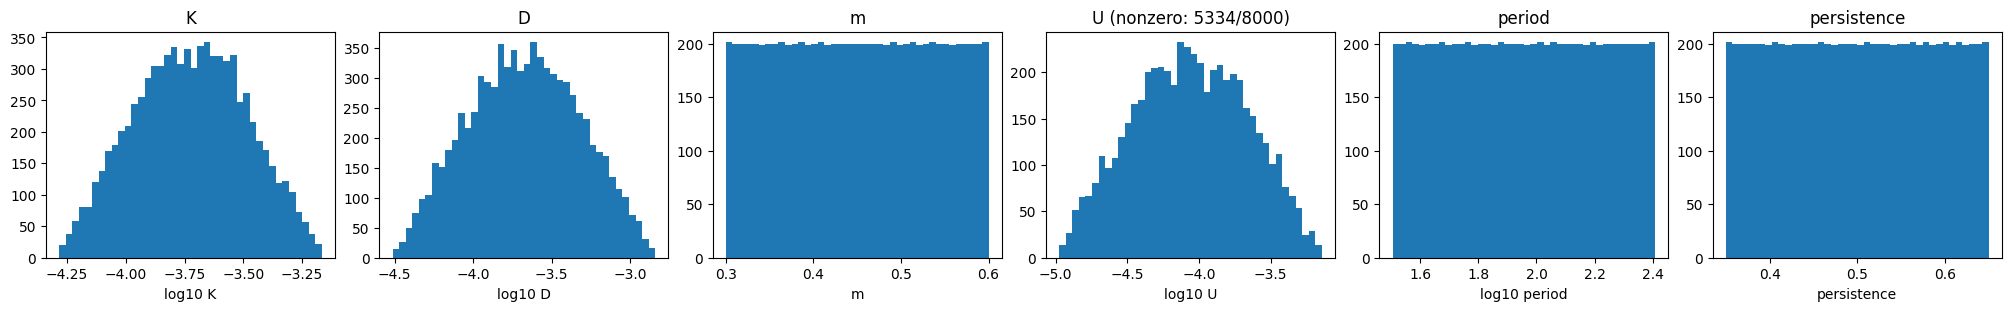

In [4]:
params = sample_params(PROFILES["full"], "train")
fig, axes = plt.subplots(1, 6, figsize=(20, 3), layout="constrained")
for ax, key in zip(axes, ["K", "D", "m", "U", "period", "persistence"]):
    values = params[key]
    log = key in ("K", "D", "period") or (key == "U")
    if key == "U":
        values = values[values > 0]
        ax.set_title(f"U (nonzero: {len(values)}/{len(params['U'])})")
    else:
        ax.set_title(key)
    ax.hist(np.log10(values) if log else values, bins=40)
    ax.set_xlabel(f"log10 {key}" if log else key)
plt.show()

## 3. One run

Run 0 of the `full` training split, simulated directly. `simulate` returns every saved snapshot.

{'K': 0.0005070248188271678, 'D': 0.0001739121161690997, 'm': 0.3757984301767597, 'U': 8.810010113175044e-05, 'period': 50.470277782831644, 'persistence': 0.4926858111139708}
snapshots: (51, 128, 128)


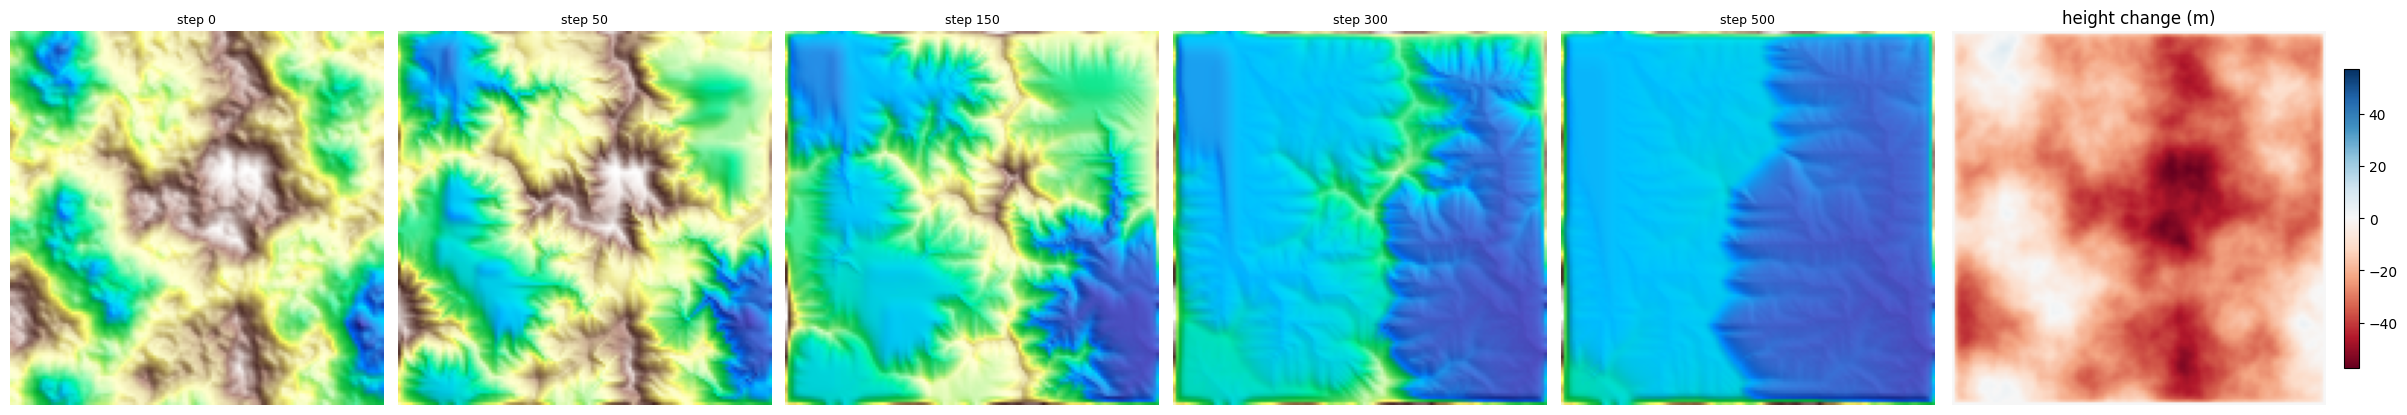

In [5]:
cfg = PROFILES["full"]
i = 0
z0 = starting_terrain(cfg, params["terrain_seed"][i], params["period"][i], params["persistence"][i])
snaps = simulate(z0, params["K"][i], params["D"][i], params["m"][i], params["U"][i],
                 dt=cfg.dt, steps=cfg.steps, snapshot_every=cfg.snapshot_every)
print({k: float(params[k][i]) for k in ["K", "D", "m", "U", "period", "persistence"]})
print("snapshots:", snaps.shape)

picks = [0, 5, 15, 30, 50]
fig, axes = plt.subplots(1, len(picks) + 1, figsize=(4 * (len(picks) + 1), 4), layout="constrained")
for ax, s in zip(axes, picks):
    hillshade(ax, snaps[s], f"step {s * cfg.snapshot_every}")
change = snaps[-1] - snaps[0]
limit = np.abs(change).max()
im = axes[-1].imshow(change, origin="lower", cmap="RdBu", vmin=-limit, vmax=limit)
axes[-1].set_title("height change (m)")
axes[-1].set_axis_off()
plt.colorbar(im, ax=axes[-1], shrink=0.8)
plt.show()

## 4. Generate and load a dataset

`make_dataset` runs every run of one split in parallel and writes three files to
`artifacts/data/<profile>/<split>/`:

- `snapshots.npy`: float32, shape (runs, snapshots, rows, cols). Load it lazily with
  `np.load(path, mmap_mode="r")`.
- `params.npz`: one array per parameter, plus `times` in years.
- `meta.json`: the config, package versions, and generation time.

The `smoke` profile takes a few seconds.

snapshots: (6, 5, 32, 32)  times (yr): [   0.  500. 1000. 1500. 2000.]
versions: {'landlab': '2.9.2', 'richdem': '0.3.4', 'numpy': '1.26.4'}  generated in 0.7 s


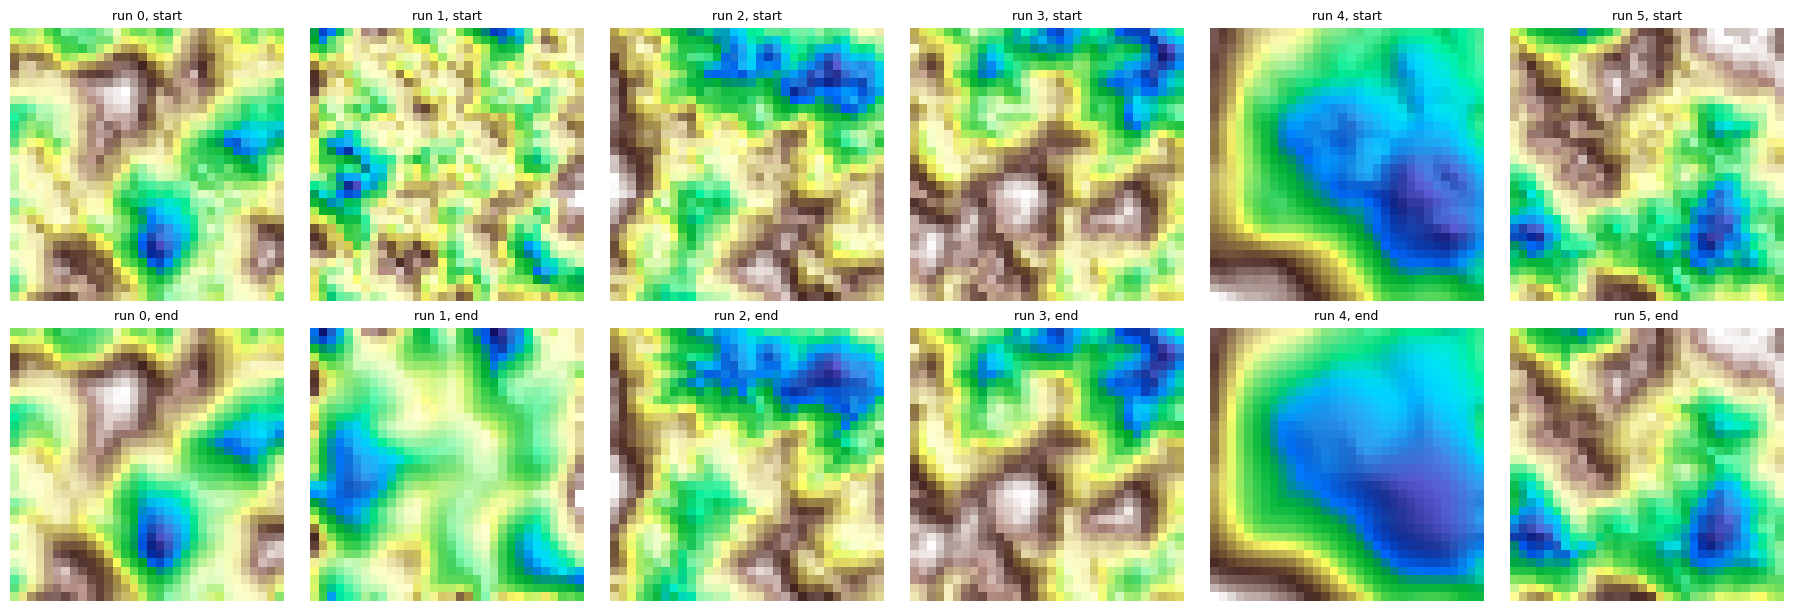

In [6]:
cfg = PROFILES["smoke"]
for split in ["train", "val", "test"]:
    make_dataset(cfg, split)
snapshots, smoke_params, meta = load_dataset(dataset_dir(cfg, "train"))
print("snapshots:", snapshots.shape, " times (yr):", smoke_params["times"])
print("versions:", meta["versions"], f" generated in {meta['seconds']:.1f} s")

fig, axes = plt.subplots(2, len(snapshots), figsize=(3 * len(snapshots), 6), layout="constrained")
for j in range(len(snapshots)):
    hillshade(axes[0, j], snapshots[j, 0], f"run {j}, start")
    hillshade(axes[1, j], snapshots[j, -1], f"run {j}, end")
plt.show()

## 5. Generate the full dataset

Off by default. The `small` profile takes about a minute on 32 cores; `full` takes about 10 minutes
and 33 GB.

In [7]:
GENERATE = None  # set to "small" or "full"

if GENERATE:
    cfg = PROFILES[GENERATE]
    for split in ["train", "val", "test"]:
        print(make_dataset(cfg, split, progress_every=max(1, cfg.runs(split) // 10)))